# Image Deblurring in the Frequency Domain (NumPy Only)
**Objective:** Simulate motion/Gaussian blur with additive noise and restore the sharp image using **Inverse Filtering** and **Wiener Deconvolution** implemented purely in **NumPy**.

### Mathematical Formulation
1. **Degradation Model:** $G(u, v) = H(u, v) \cdot F(u, v) + N(u, v)$
2. **Wiener Filter Restoration:**
   $$\hat{F}(u, v) = \left[ \frac{H^*(u, v)}{|H(u, v)|^2 + K} \right] G(u, v)$$
   where $H^*(u, v)$ is the complex conjugate of the Point Spread Function (PSF) in the frequency domain, and $K$ is the noise-to-signal power ratio damping constant.

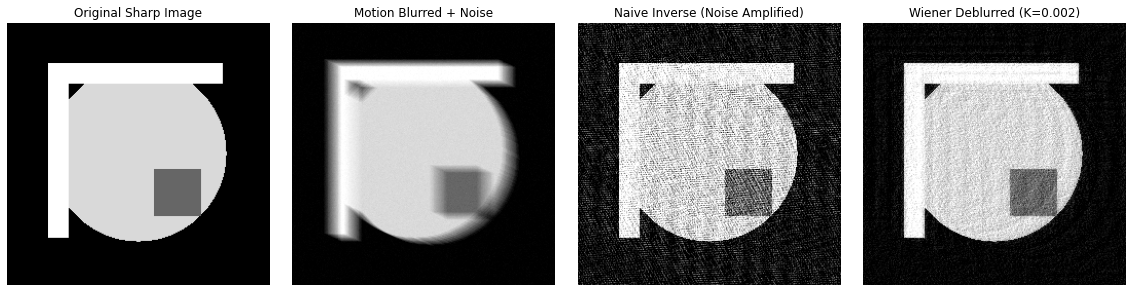

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a sharp synthetic grayscale test image (256x256) with crisp edges
N = 256
x = np.linspace(-1, 1, N)
X, Y = np.meshgrid(x, x)

sharp_img = np.zeros((N, N), dtype=np.float32)
sharp_img[(X**2 + Y**2) < 0.45] = 0.85                                   # Circle
sharp_img[(np.abs(X - 0.3) < 0.18) & (np.abs(Y - 0.3) < 0.18)] = 0.4     # Square
sharp_img[40:60, 40:210] = 1.0                                           # Horizontal bar
sharp_img[40:210, 40:60] = 1.0                                           # Vertical bar

# 2. Define a 2D Motion Blur Point Spread Function (PSF) kernel
def create_motion_psf(shape, length=15, angle=30):
    psf = np.zeros(shape, dtype=np.float32)
    center = (shape[0] // 2, shape[1] // 2)
    theta = np.deg2rad(angle)
    
    for i in range(-length // 2, length // 2 + 1):
        r = int(round(center[0] + i * np.sin(theta)))
        c = int(round(center[1] + i * np.cos(theta)))
        if 0 <= r < shape[0] and 0 <= c < shape[1]:
            psf[r, c] = 1.0
            
    psf /= np.sum(psf)  # Normalize energy to 1
    return psf

psf = create_motion_psf((N, N), length=19, angle=25)

# 3. Blur the image in the frequency domain and add slight sensor noise
F_sharp = np.fft.fft2(sharp_img)
H = np.fft.fft2(np.fft.ifftshift(psf))  # Shift PSF center to (0,0) before FFT

rng = np.random.default_rng(seed=42)
noise = rng.normal(0.0, 0.01, sharp_img.shape).astype(np.float32)

blurred_img = np.real(np.fft.ifft2(F_sharp * H)) + noise
blurred_img = np.clip(blurred_img, 0.0, 1.0)

# 4. Deblurring Function: Wiener Filter (NumPy Only)
def wiener_deblur_numpy(blurred: np.ndarray, psf: np.ndarray, K: float = 0.002) -> np.ndarray:
    G = np.fft.fft2(blurred)
    H = np.fft.fft2(np.fft.ifftshift(psf))
    
    # Wiener transfer function: H* / (|H|^2 + K)
    H_conj = np.conj(H)
    H_mag_sq = np.abs(H) ** 2
    wiener_filter = H_conj / (H_mag_sq + K)
    
    # Reconstruct sharp image
    F_hat = G * wiener_filter
    restored = np.real(np.fft.ifft2(F_hat))
    return np.clip(restored, 0.0, 1.0)

# Compare Naive Inverse Filter (K ≈ 0) vs. Wiener Filter (K = 0.002)
naive_inverse = wiener_deblur_numpy(blurred_img, psf, K=1e-7)
wiener_restored = wiener_deblur_numpy(blurred_img, psf, K=0.002)

# 5. Visualize Sharp, Blurred, Naive Inverse, and Wiener Deblurred Outputs
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
outputs = [
    ("Original Sharp Image", sharp_img),
    ("Motion Blurred + Noise", blurred_img),
    ("Naive Inverse (Noise Amplified)", naive_inverse),
    ("Wiener Deblurred (K=0.002)", wiener_restored),
]

for ax, (title, im) in zip(axes, outputs):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()